In [2]:
import csv
import math
import statistics
from pathlib import Path


import matplotlib.pyplot as plt

In [3]:
# Resolve paths whether the kernel starts at the home, repository, or notebook directory.
working_dir = Path.cwd()
candidate_roots = [working_dir, working_dir / "ai4mi_project", working_dir.parent]
project_root = next(
    (root for root in candidate_roots
     if (root / "results/heldout_predictions/metrics").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate results/heldout_predictions/metrics from "
        f"the current directory ({working_dir})."
    )

metrics_before_path = project_root / "results/heldout_predictions/metrics"

# contains CSV metric files for each model after postprocessing
metrics_after_path = project_root / "results/heldout_predictions/metrics_postprocessed"

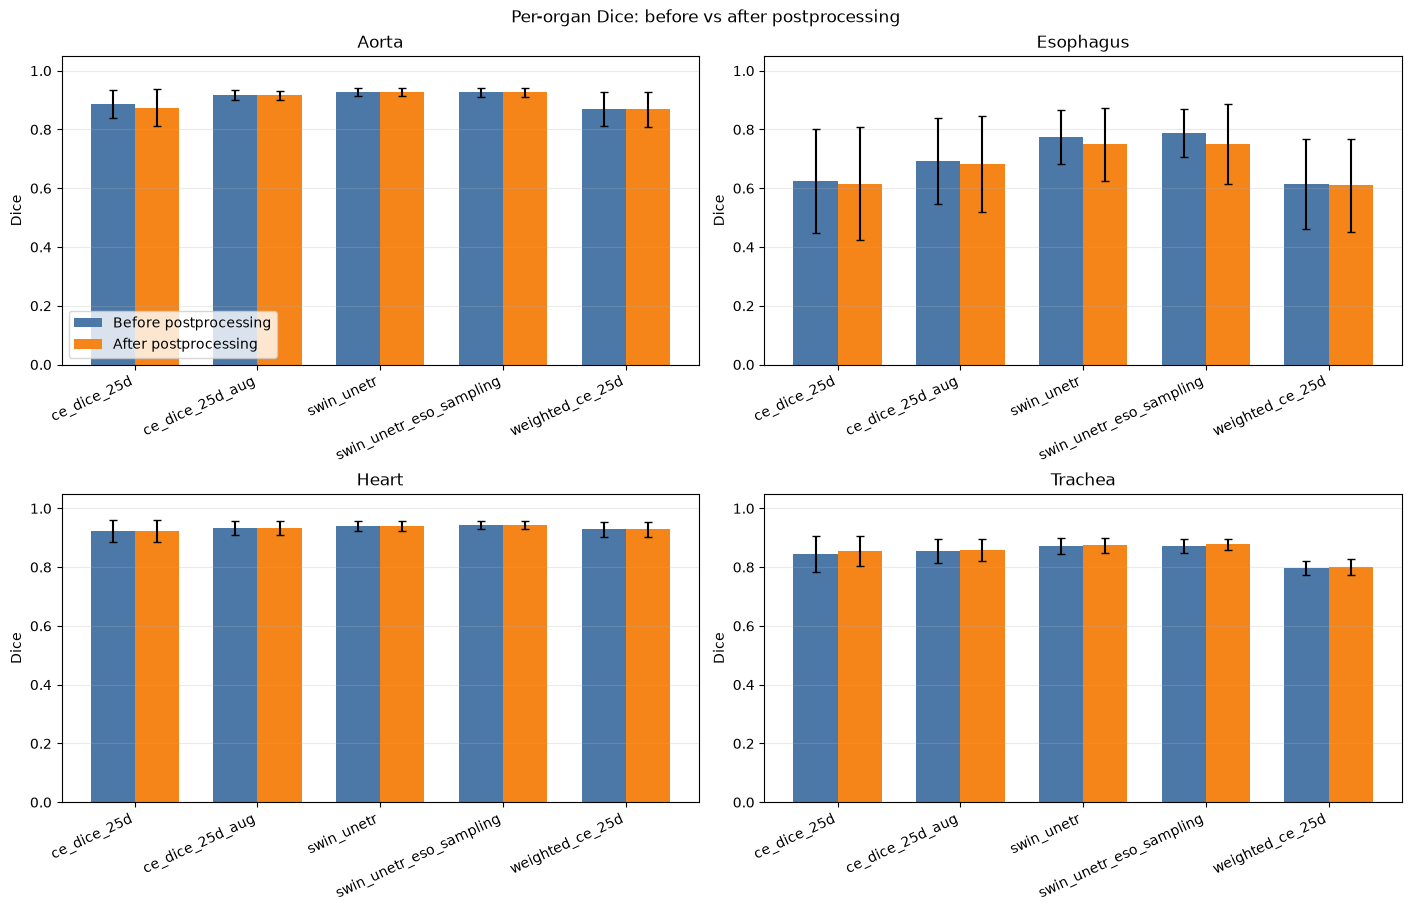

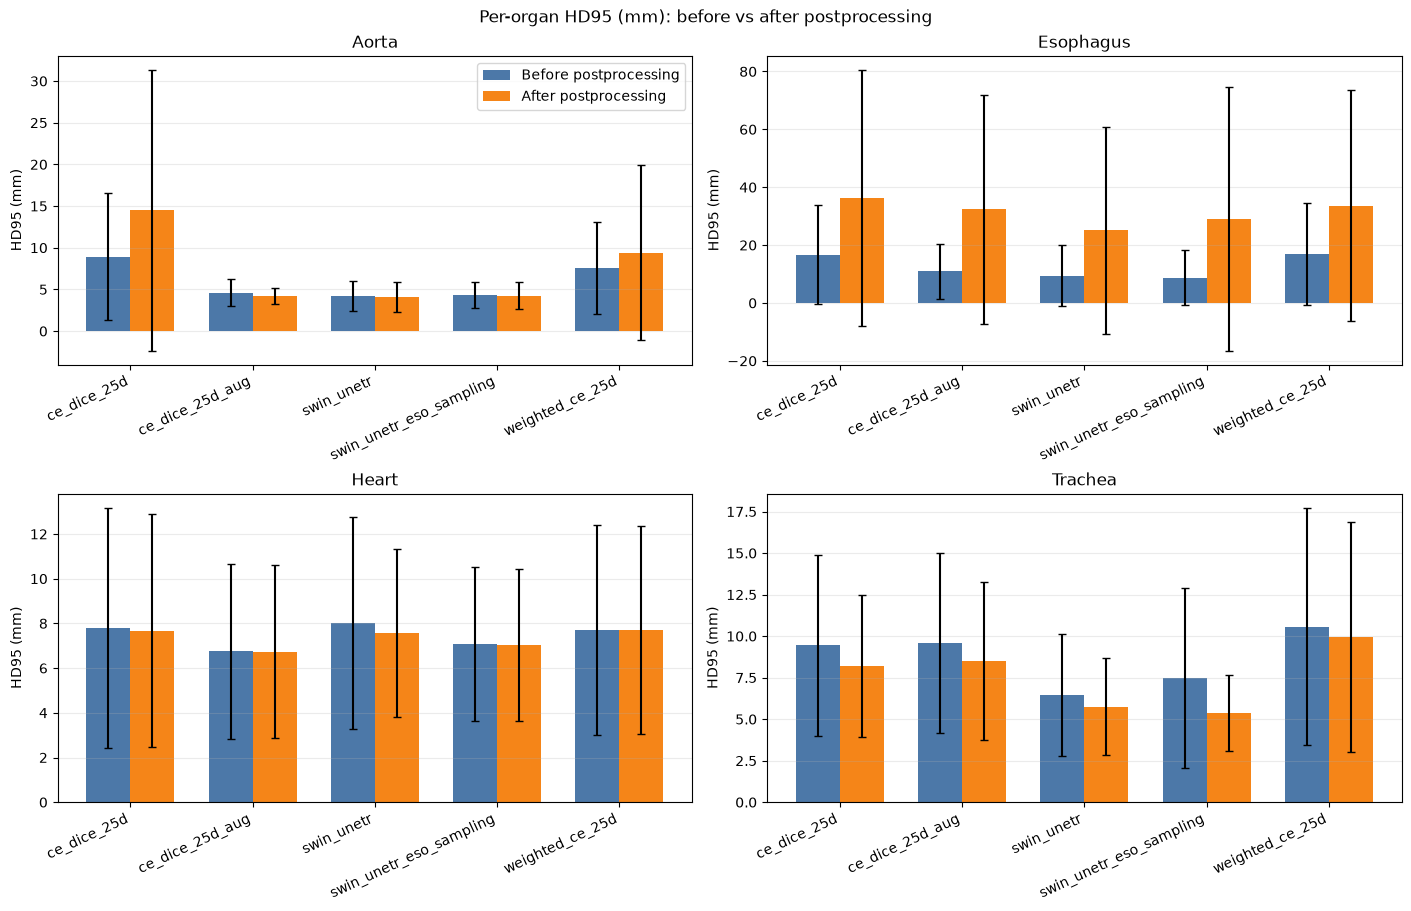

In [3]:
def read_metric_csv(path):
    # add prediction voxels
    required_columns = {"patient", "organ", "dice", "hd95_mm"}
    with path.open(newline="", encoding="utf-8") as metric_file:
        reader = csv.DictReader(metric_file)
        if not required_columns.issubset(reader.fieldnames or []):
            raise ValueError(
                f"{path} must contain these columns: {sorted(required_columns)}"
            )
        return list(reader)


before_files = {path.stem: path for path in metrics_before_path.glob("*.csv")}
after_files = {path.stem: path for path in metrics_after_path.glob("*.csv")}
paired_models = sorted(before_files.keys() & after_files.keys())

if not paired_models:
    raise FileNotFoundError(
        "No model has both a before and after CSV. Check the metric directories:\n"
        f"  before: {metrics_before_path}\n  after: {metrics_after_path}"
    )

missing_after = sorted(before_files.keys() - after_files.keys())
missing_before = sorted(after_files.keys() - before_files.keys())
if missing_after:
    print("Skipping models without postprocessed CSVs:", ", ".join(missing_after))
if missing_before:
    print("Skipping postprocessed CSVs without baseline CSVs:", ", ".join(missing_before))

metrics = {
    "before": {model: read_metric_csv(before_files[model]) for model in paired_models},
    "after": {model: read_metric_csv(after_files[model]) for model in paired_models},
}
metric_columns = {"Dice": "dice", "HD95 (mm)": "hd95_mm"}
organs = sorted({
    row["organ"]
    for condition in metrics.values()
    for rows in condition.values()
    for row in rows
    if row["organ"].lower() != "background"
})

def mean_and_std(rows, column, organ):
    values = [
        float(row[column])
        for row in rows
        if row["organ"] == organ
        and row[column].strip().lower() not in {"", "nan", "none"}
        and math.isfinite(float(row[column]))
    ]
    if not values:
        return math.nan, 0.0
    return statistics.mean(values), statistics.stdev(values) if len(values) > 1 else 0.0

x = list(range(len(paired_models)))
bar_width = 0.36
for metric_label, column in metric_columns.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    axes = axes.ravel()
    for ax, organ in zip(axes, organs):
        for offset, condition, label, color in [
            (-bar_width / 2, "before", "Before postprocessing", "#4C78A8"),
            (bar_width / 2, "after", "After postprocessing", "#F58518"),
        ]:
            stats = [
                mean_and_std(metrics[condition][model], column, organ)
                for model in paired_models
            ]
            means = [item[0] for item in stats]
            errors = [item[1] for item in stats]
            ax.bar(
                [position + offset for position in x], means, bar_width,
                yerr=errors, capsize=3, label=label, color=color,
            )
        ax.set_title(organ.capitalize())
        ax.set_xticks(x, paired_models, rotation=25, ha="right")
        ax.set_ylabel(metric_label)
        ax.grid(axis="y", alpha=0.25)
        if metric_label == "Dice":
            ax.set_ylim(0, 1.05)
    for ax in axes[len(organs):]:
        ax.set_visible(False)
    axes[0].legend()
    fig.suptitle(f"Per-organ {metric_label}: before vs after postprocessing")
    plt.show()

## Close esophagus effect

In [4]:
# Resolve paths whether the kernel starts at the home, repository, or notebook directory.
working_dir = Path.cwd()
candidate_roots = [working_dir, working_dir / "ai4mi_project", working_dir.parent]
project_root = next(
    (root for root in candidate_roots
     if (root / "results/heldout_predictions/metrics").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate results/heldout_predictions/metrics from "
        f"the current directory ({working_dir})."
    )

metrics_before_path = project_root / "results/heldout_predictions/metrics"

# contains CSV metric files for each model after postprocessing
metrics_after_path = project_root / "results/heldout_predictions/metrics_postprocessed"

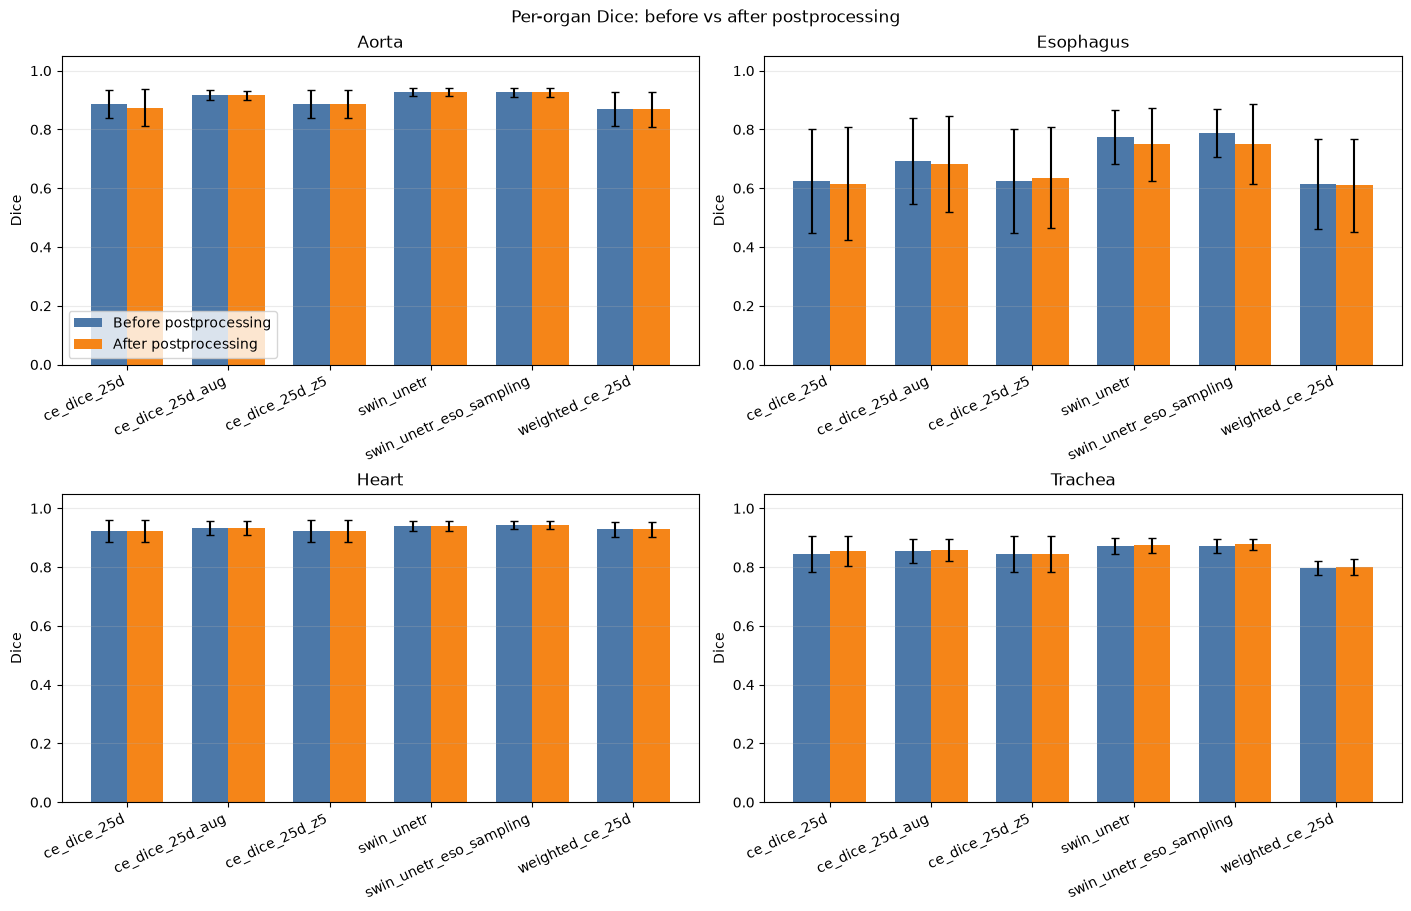

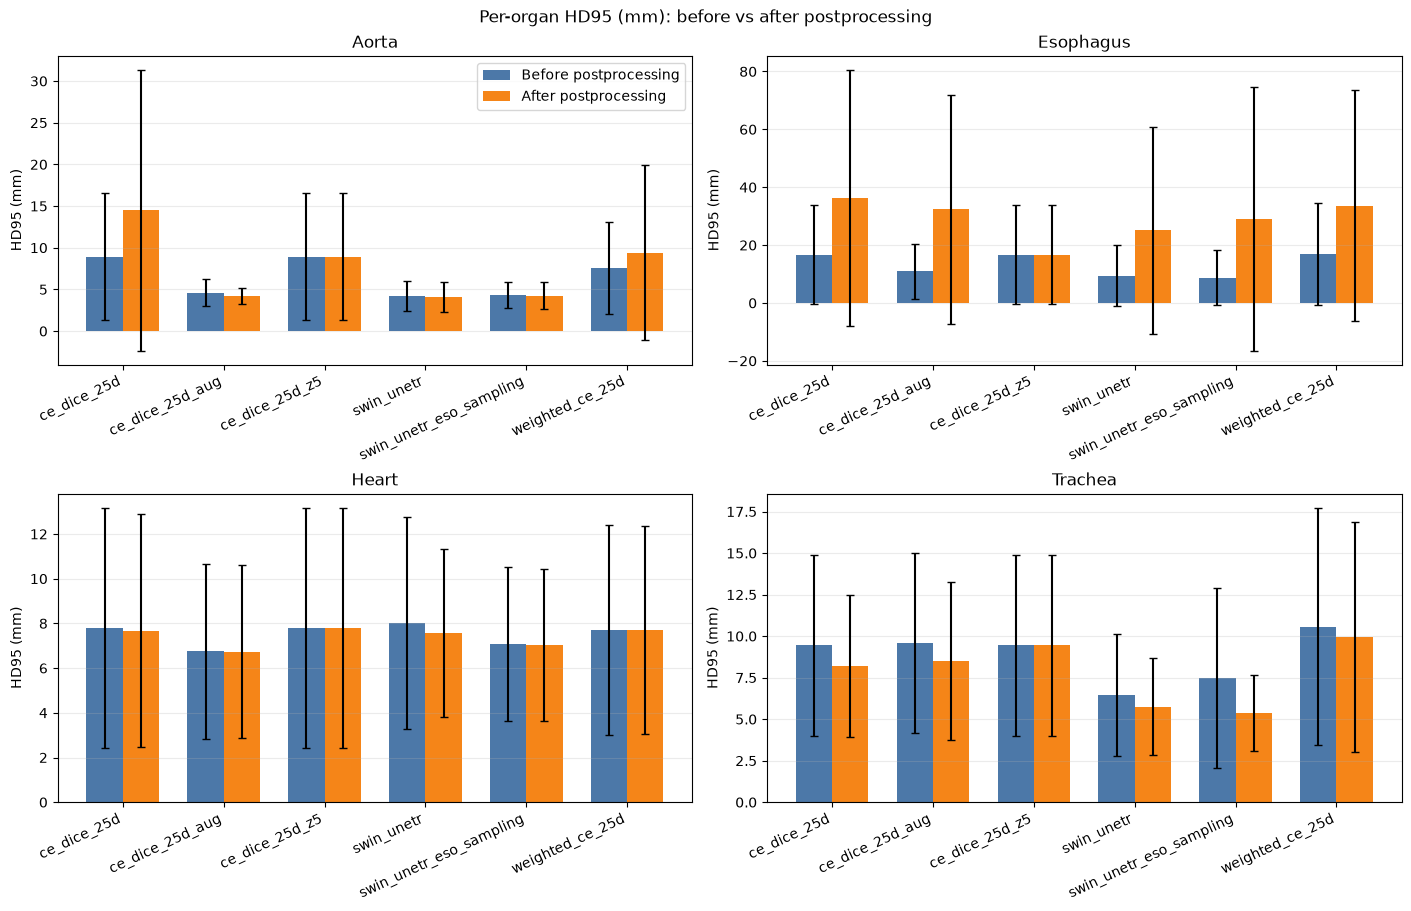

In [5]:
def read_metric_csv(path):
    # add prediction voxels
    required_columns = {"patient", "organ", "dice", "hd95_mm"}
    with path.open(newline="", encoding="utf-8") as metric_file:
        reader = csv.DictReader(metric_file)
        if not required_columns.issubset(reader.fieldnames or []):
            raise ValueError(
                f"{path} must contain these columns: {sorted(required_columns)}"
            )
        return list(reader)


before_files = {path.stem: path for path in metrics_before_path.glob("*.csv")}
after_files = {path.stem: path for path in metrics_after_path.glob("*.csv")}
paired_models = sorted(before_files.keys() & after_files.keys())

if not paired_models:
    raise FileNotFoundError(
        "No model has both a before and after CSV. Check the metric directories:\n"
        f"  before: {metrics_before_path}\n  after: {metrics_after_path}"
    )

missing_after = sorted(before_files.keys() - after_files.keys())
missing_before = sorted(after_files.keys() - before_files.keys())
if missing_after:
    print("Skipping models without postprocessed CSVs:", ", ".join(missing_after))
if missing_before:
    print("Skipping postprocessed CSVs without baseline CSVs:", ", ".join(missing_before))

metrics = {
    "before": {model: read_metric_csv(before_files[model]) for model in paired_models},
    "after": {model: read_metric_csv(after_files[model]) for model in paired_models},
}
metric_columns = {"Dice": "dice", "HD95 (mm)": "hd95_mm"}
organs = sorted({
    row["organ"]
    for condition in metrics.values()
    for rows in condition.values()
    for row in rows
    if row["organ"].lower() != "background"
})

def mean_and_std(rows, column, organ):
    values = [
        float(row[column])
        for row in rows
        if row["organ"] == organ
        and row[column].strip().lower() not in {"", "nan", "none"}
        and math.isfinite(float(row[column]))
    ]
    if not values:
        return math.nan, 0.0
    return statistics.mean(values), statistics.stdev(values) if len(values) > 1 else 0.0

x = list(range(len(paired_models)))
bar_width = 0.36
for metric_label, column in metric_columns.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    axes = axes.ravel()
    for ax, organ in zip(axes, organs):
        for offset, condition, label, color in [
            (-bar_width / 2, "before", "Before postprocessing", "#4C78A8"),
            (bar_width / 2, "after", "After postprocessing", "#F58518"),
        ]:
            stats = [
                mean_and_std(metrics[condition][model], column, organ)
                for model in paired_models
            ]
            means = [item[0] for item in stats]
            errors = [item[1] for item in stats]
            ax.bar(
                [position + offset for position in x], means, bar_width,
                yerr=errors, capsize=3, label=label, color=color,
            )
        ax.set_title(organ.capitalize())
        ax.set_xticks(x, paired_models, rotation=25, ha="right")
        ax.set_ylabel(metric_label)
        ax.grid(axis="y", alpha=0.25)
        if metric_label == "Dice":
            ax.set_ylim(0, 1.05)
    for ax in axes[len(organs):]:
        ax.set_visible(False)
    axes[0].legend()
    fig.suptitle(f"Per-organ {metric_label}: before vs after postprocessing")
    plt.show()

In [6]:
# Resolve paths whether the kernel starts at the home, repository, or notebook directory.
working_dir = Path.cwd()
candidate_roots = [working_dir, working_dir / "ai4mi_project", working_dir.parent]
project_root = next(
    (root for root in candidate_roots
     if (root / "results/heldout_predictions/metrics").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Could not locate results/heldout_predictions/metrics from "
        f"the current directory ({working_dir})."
    )

metrics_before_path = project_root / "results/heldout_predictions/metrics"

# contains CSV metric files for each model after postprocessing
metrics_after_path = project_root / "results/heldout_final_metrics"

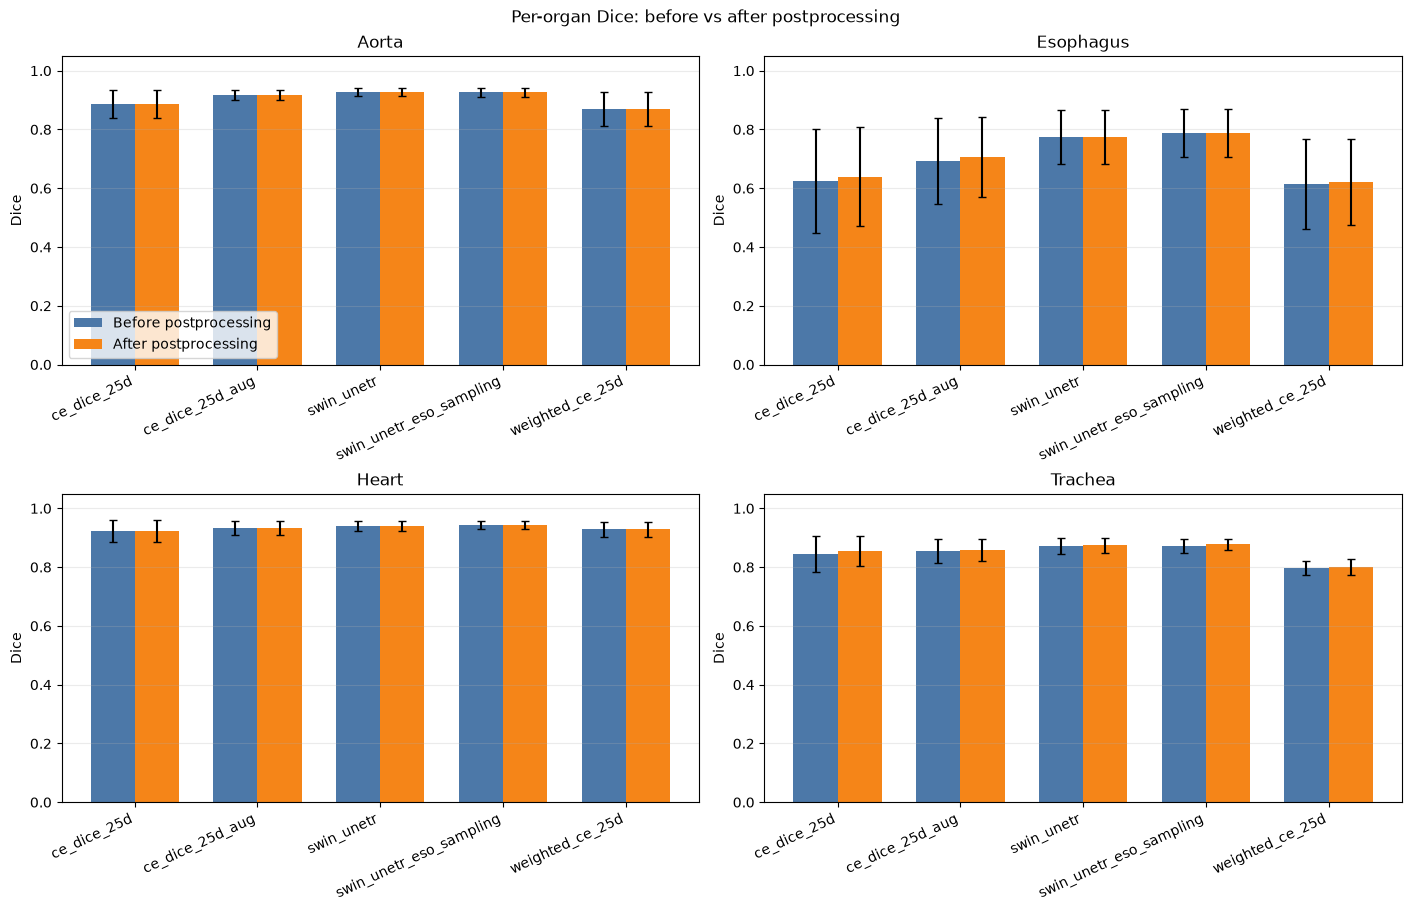

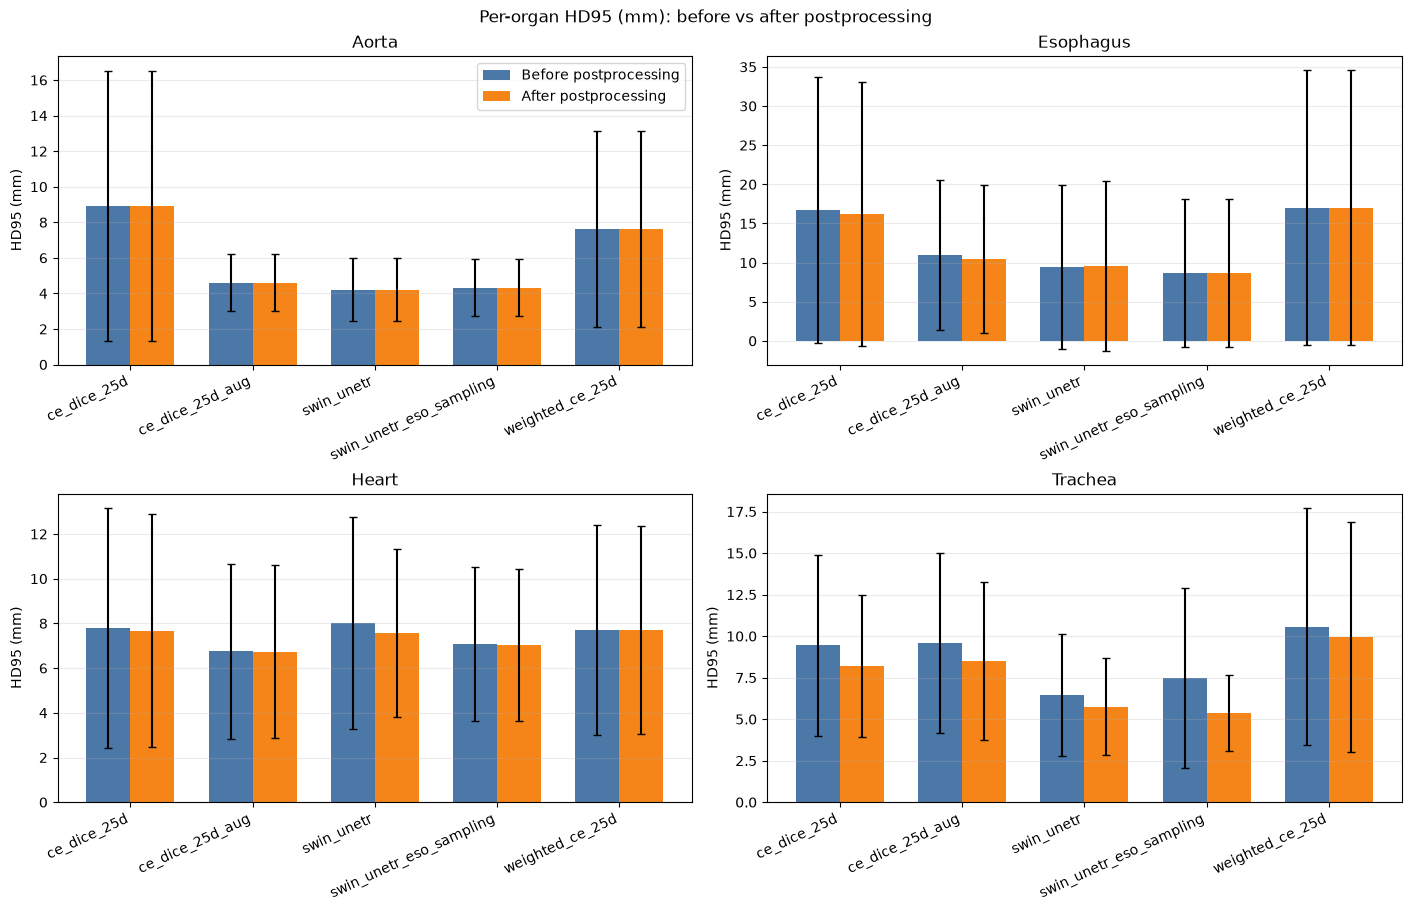

In [7]:
def read_metric_csv(path):
    # add prediction voxels
    required_columns = {"patient", "organ", "dice", "hd95_mm"}
    with path.open(newline="", encoding="utf-8") as metric_file:
        reader = csv.DictReader(metric_file)
        if not required_columns.issubset(reader.fieldnames or []):
            raise ValueError(
                f"{path} must contain these columns: {sorted(required_columns)}"
            )
        return list(reader)


before_files = {path.stem: path for path in metrics_before_path.glob("*.csv")}
after_files = {path.stem: path for path in metrics_after_path.glob("*.csv")}
paired_models = sorted(before_files.keys() & after_files.keys())

if not paired_models:
    raise FileNotFoundError(
        "No model has both a before and after CSV. Check the metric directories:\n"
        f"  before: {metrics_before_path}\n  after: {metrics_after_path}"
    )

missing_after = sorted(before_files.keys() - after_files.keys())
missing_before = sorted(after_files.keys() - before_files.keys())
if missing_after:
    print("Skipping models without postprocessed CSVs:", ", ".join(missing_after))
if missing_before:
    print("Skipping postprocessed CSVs without baseline CSVs:", ", ".join(missing_before))

metrics = {
    "before": {model: read_metric_csv(before_files[model]) for model in paired_models},
    "after": {model: read_metric_csv(after_files[model]) for model in paired_models},
}
metric_columns = {"Dice": "dice", "HD95 (mm)": "hd95_mm"}
organs = sorted({
    row["organ"]
    for condition in metrics.values()
    for rows in condition.values()
    for row in rows
    if row["organ"].lower() != "background"
})

def mean_and_std(rows, column, organ):
    values = [
        float(row[column])
        for row in rows
        if row["organ"] == organ
        and row[column].strip().lower() not in {"", "nan", "none"}
        and math.isfinite(float(row[column]))
    ]
    if not values:
        return math.nan, 0.0
    return statistics.mean(values), statistics.stdev(values) if len(values) > 1 else 0.0

x = list(range(len(paired_models)))
bar_width = 0.36
for metric_label, column in metric_columns.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
    axes = axes.ravel()
    for ax, organ in zip(axes, organs):
        for offset, condition, label, color in [
            (-bar_width / 2, "before", "Before postprocessing", "#4C78A8"),
            (bar_width / 2, "after", "After postprocessing", "#F58518"),
        ]:
            stats = [
                mean_and_std(metrics[condition][model], column, organ)
                for model in paired_models
            ]
            means = [item[0] for item in stats]
            errors = [item[1] for item in stats]
            ax.bar(
                [position + offset for position in x], means, bar_width,
                yerr=errors, capsize=3, label=label, color=color,
            )
        ax.set_title(organ.capitalize())
        ax.set_xticks(x, paired_models, rotation=25, ha="right")
        ax.set_ylabel(metric_label)
        ax.grid(axis="y", alpha=0.25)
        if metric_label == "Dice":
            ax.set_ylim(0, 1.05)
    for ax in axes[len(organs):]:
        ax.set_visible(False)
    axes[0].legend()
    fig.suptitle(f"Per-organ {metric_label}: before vs after postprocessing")
    plt.show()

## Compare per patient

In [5]:
def read_metric_csv(path):
    # add prediction voxels
    required_columns = {"patient", "organ", "dice", "hd95_mm"}
    with path.open(newline="", encoding="utf-8") as metric_file:
        reader = csv.DictReader(metric_file)
        if not required_columns.issubset(reader.fieldnames or []):
            raise ValueError(
                f"{path} must contain these columns: {sorted(required_columns)}"
            )
        return list(reader)

In [6]:
metrics_before_path = project_root / "results/heldout_predictions/metrics"
metrics_after_path = project_root / "results/heldout_final_metrics"

before_files = {path.stem: path for path in metrics_before_path.glob("*.csv")}
after_files = {path.stem: path for path in metrics_after_path.glob("*.csv")}
paired_models = sorted(before_files.keys() & after_files.keys())
missing_after = sorted(before_files.keys() - after_files.keys())
missing_before = sorted(after_files.keys() - before_files.keys())
if missing_after:
    print("Skipping models without final-metrics CSVs:", ", ".join(missing_after))
if missing_before:
    print("Skipping final-metrics CSVs without baseline CSVs:", ", ".join(missing_before))
if not paired_models:
    raise FileNotFoundError(
        "No model has both a before and after CSV. Check the metric directories:\n"
        f"  before: {metrics_before_path}\n  after: {metrics_after_path}"
    )

def finite_mean(rows, column):
    values = [
        float(row[column])
        for row in rows
        if row["organ"].lower() != "background"
        and row[column].strip().lower() not in {"", "nan", "none"}
        and math.isfinite(float(row[column]))
    ]
    return statistics.mean(values) if values else math.nan


patient_summary = []
for model in paired_models:
    before_rows = read_metric_csv(before_files[model])
    after_rows = read_metric_csv(after_files[model])
    before_keys = {(row["patient"], row["organ"]) for row in before_rows}
    after_keys = {(row["patient"], row["organ"]) for row in after_rows}
    if before_keys != after_keys:
        raise ValueError(f"Patient/organ rows do not match for {model}.")
    before_by_patient, after_by_patient = {}, {}
    for row in before_rows:
        before_by_patient.setdefault(row["patient"], []).append(row)
    for row in after_rows:
        after_by_patient.setdefault(row["patient"], []).append(row)
    if before_by_patient.keys() != after_by_patient.keys():
        raise ValueError(f"Patient sets do not match for {model}.")

    for patient in sorted(before_by_patient):
        dice_before = finite_mean(before_by_patient[patient], "dice")
        dice_after = finite_mean(after_by_patient[patient], "dice")
        hd95_before = finite_mean(before_by_patient[patient], "hd95_mm")
        hd95_after = finite_mean(after_by_patient[patient], "hd95_mm")
        patient_summary.append({
            "model": model, "patient": patient,
            "dice_before": dice_before, "dice_after": dice_after,
            "dice_delta": dice_after - dice_before,
            "hd95_before": hd95_before, "hd95_after": hd95_after,
            "hd95_delta": hd95_after - hd95_before,
        })


def show_patient_table(title, rows):
    print(f"\n{title}")
    print("Patient      | Dice before -> after (Δ) | HD95 before -> after (Δ mm)")
    print("-------------|--------------------------|--------------------------")
    for row in rows:
        print(
            f"{row['patient']:<12} | "
            f"{row['dice_before']:.4f} -> {row['dice_after']:.4f} "
            f"({row['dice_delta']:+.4f}) | "
            f"{row['hd95_before']:.3f} -> {row['hd95_after']:.3f} "
            f"({row['hd95_delta']:+.3f})"
        )


TOP_N = 5
for model in paired_models:
    model_patients = [row for row in patient_summary if row["model"] == model]
    print(f"\n{'=' * 24} {model} {'=' * 24}")
    show_patient_table(
        "All patients (mean across foreground organs; background excluded)",
        model_patients,
    )
    show_patient_table(
        f"Top {TOP_N} Dice improvements",
        sorted(model_patients, key=lambda row: row["dice_delta"], reverse=True)[:TOP_N],
    )
    show_patient_table(
        f"Top {TOP_N} Dice regressions / least improved",
        sorted(model_patients, key=lambda row: row["dice_delta"])[:TOP_N],
    )
    show_patient_table(
        f"Top {TOP_N} HD95 improvements (largest reductions)",
        sorted(model_patients, key=lambda row: row["hd95_delta"])[:TOP_N],
    )
    show_patient_table(
        f"Top {TOP_N} HD95 regressions (largest increases)",
        sorted(model_patients, key=lambda row: row["hd95_delta"], reverse=True)[:TOP_N],
    )
    show_patient_table(
        f"Top {TOP_N} closest to no change (by absolute mean Dice change)",
        sorted(model_patients, key=lambda row: abs(row["dice_delta"]))[:TOP_N],
    )


======================== ce_dice_25d ========================

All patients (mean across foreground organs; background excluded)
Patient      | Dice before -> after (Δ) | HD95 before -> after (Δ mm)
-------------|--------------------------|--------------------------
Patient_03   | 0.7167 -> 0.7274 (+0.0107) | 14.061 -> 13.017 (-1.044)
Patient_17   | 0.8708 -> 0.8719 (+0.0011) | 6.054 -> 5.875 (-0.179)
Patient_20   | 0.7246 -> 0.7294 (+0.0048) | 22.518 -> 22.351 (-0.167)
Patient_25   | 0.8284 -> 0.8280 (-0.0004) | 11.190 -> 11.202 (+0.012)
Patient_26   | 0.8883 -> 0.8889 (+0.0006) | 6.055 -> 6.080 (+0.025)
Patient_27   | 0.8459 -> 0.8509 (+0.0050) | 4.922 -> 4.882 (-0.040)
Patient_32   | 0.8700 -> 0.8746 (+0.0045) | 11.415 -> 11.409 (-0.006)
Patient_33   | 0.8133 -> 0.8354 (+0.0222) | 9.591 -> 7.180 (-2.412)

Top 5 Dice improvements
Patient      | Dice before -> after (Δ) | HD95 before -> after (Δ mm)
-------------|--------------------------|--------------------------
Patient_33   | 0.

In [7]:
import pandas as pd
from IPython.display import display

ORGAN_ORDER = ["esophagus", "heart", "trachea", "aorta"]
SWIN = "swin_unetr"
SWIN_MODELS = ["swin_unetr_eso_sampling", "swin_unetr"]
OUT_DIR = project_root / "results/heldout_final_comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def to_float(text):
    try:
        return float(text)
    except (TypeError, ValueError):
        return math.nan


def add_gains(df):
    df["dice_gain"] = df["dice_after"] - df["dice_before"]    # > 0 is better
    df["hd95_gain"] = df["hd95_before"] - df["hd95_after"]    # > 0 is better (mm removed)
    return df


patients = add_gains(
    pd.DataFrame(patient_summary).drop(columns=["dice_delta", "hd95_delta"])
)

organ_rows = []
for model in paired_models:
    before = {(r["patient"], r["organ"].lower()): r for r in read_metric_csv(before_files[model])}
    after = {(r["patient"], r["organ"].lower()): r for r in read_metric_csv(after_files[model])}
    for (patient, organ), row in before.items():
        if organ == "background":
            continue
        organ_rows.append({
            "model": model, "patient": patient, "organ": organ,
            "dice_before": to_float(row["dice"]),
            "dice_after": to_float(after[(patient, organ)]["dice"]),
            "hd95_before": to_float(row["hd95_mm"]),
            "hd95_after": to_float(after[(patient, organ)]["hd95_mm"]),
        })
organs = add_gains(pd.DataFrame(organ_rows))
organs["organ"] = pd.Categorical(organs["organ"], ORGAN_ORDER, ordered=True)

cols = ["dice_before", "dice_after", "dice_gain", "hd95_before", "hd95_after", "hd95_gain"]

# Table 1: mean per model
table1 = patients.groupby("model")[cols].mean().round(4).reset_index()

# Table 2: best 3 improved patients for swin_unetr (by Dice gain)
assert SWIN in paired_models, f"{SWIN} not in {paired_models}"
swin = patients[patients["model"] == SWIN]
n_improved = int((swin["dice_gain"] > 0).sum())
table2 = (
    swin[swin["dice_gain"] > 0]
    .nlargest(3, "dice_gain")[["patient"] + cols]
    .round(4)
    .reset_index(drop=True)
)

# Table 3: per organ for the two Swin models
table3 = (
    organs[organs["model"].isin(SWIN_MODELS)]
    .groupby(["model", "organ"], observed=True)[cols]
    .mean()
    .round(4)
    .reset_index()
)

print("Table 1: mean over patients and foreground organs, per model")
display(table1)
print(f"\nTable 2: {SWIN}, top 3 by Dice gain ({n_improved} of {len(swin)} patients improved in Dice)")
display(table2)
print("\nTable 3: mean over patients, per organ")
display(table3)

table1.to_csv(OUT_DIR / "table1_mean_per_model.csv", index=False)
table2.to_csv(OUT_DIR / "table2_swin_unetr_top3_patients.csv", index=False)
table3.to_csv(OUT_DIR / "table3_swin_models_per_organ.csv", index=False)
print(f"\nSaved 3 CSVs to {OUT_DIR}")

Table 1: mean over patients and foreground organs, per model


,model,dice_before,dice_after,dice_gain,hd95_before,hd95_after,hd95_gain
0,ce_dice_25d,0.8198,0.8258,0.0061,10.7259,10.2494,0.4765
1,ce_dice_25d_aug,0.8493,0.8536,0.0043,7.9689,7.5731,0.3958
2,swin_unetr,0.8783,0.8792,0.0009,7.0381,6.7815,0.2567
3,swin_unetr_eso_sampling,0.8817,0.8832,0.0016,6.8895,6.3424,0.5471
4,weighted_ce_25d,0.8021,0.8042,0.0021,10.7242,10.5702,0.1540



Table 2: swin_unetr, top 3 by Dice gain (5 of 8 patients improved in Dice)


,patient,dice_before,dice_after,dice_gain,hd95_before,hd95_after,hd95_gain
0,Patient_33,0.8641,0.8672,0.0031,7.5886,7.0804,0.5083
1,Patient_32,0.8970,0.8995,0.0026,5.7526,5.0618,0.6908
2,Patient_20,0.8391,0.8415,0.0024,11.4154,10.3037,1.1117



Table 3: mean over patients, per organ


,model,organ,dice_before,dice_after,dice_gain,hd95_before,hd95_after,hd95_gain
0,swin_unetr,esophagus,0.7753,0.7754,0.0002,9.4656,9.5944,-0.1288
1,swin_unetr,heart,0.9397,0.9399,0.0002,8.0235,7.5677,0.4558
2,swin_unetr,trachea,0.8708,0.8742,0.0034,6.4444,5.7448,0.6997
3,swin_unetr,aorta,0.9273,0.9273,0.0000,4.2189,4.2189,0.0000
4,swin_unetr_eso_sampling,esophagus,0.7869,0.7873,0.0005,8.6817,8.6312,0.0505
5,swin_unetr_eso_sampling,heart,0.9421,0.9421,0.0000,7.0672,7.0410,0.0262
6,swin_unetr_eso_sampling,trachea,0.8715,0.8774,0.0059,7.4781,5.3666,2.1116
7,swin_unetr_eso_sampling,aorta,0.9262,0.9262,0.0000,4.3310,4.3310,0.0000



Saved 3 CSVs to /gpfs/home6/scur0199/ai4mi_project/results/heldout_final_comparison
